# K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN，K 近鄰演算法) 是一種非常適合機器學習初學者的演算法。它不需要複雜的數學推導，核心概念就是「看看一筆新資料附近的 K 個鄰居，再根據這些鄰居的結果做出預測。」

## 什麼是 K-Nearest Neighbors (KNN)？

KNN 是一種監督式機器學習演算法 (Supervised Machine Learning)，可以用來處理分類與迴歸問題。它的判斷方式很直覺。

假設我們想知道一位學生是否會及格，可以參考過去學生的資料：

| 學生 | 每日讀書時數 | 出席率 | 是否及格 |
|---|---|---|---|
| A | 1.5 | 55% | 不及格 |
| B | 2.0 | 60% | 不及格 |
| C | 5.5 | 85% | 及格 |
| D | 6.0 | 90% | 及格 |
| E | 7.0 | 95% | 及格 |

現在有一位新學生：

```text
每日讀書時數：6.2 小時
出席率：88%
```

如果只觀察讀書時數與出席率，這位學生比較接近 C、D、E，而不是 A、B。因此，KNN 可能判斷這位學生會及格。

這個概念可以整理成：
$$
\boxed{
\text{新學生資料}
\longrightarrow
\text{尋找最近的 K 個鄰居}
\longrightarrow
\text{預測是否及格}
}
$$

### KNN 可以應用在哪些問題？

| 應用情境 | Features | Target | 類型 |
|---|---|---|---|
| 學生是否及格 | 讀書時數、出席率 | 及格 / 不及格 | Classification |
| 顧客是否購買 | 年齡、收入、瀏覽次數 | 購買 / 不購買 | Classification |
| 鳶尾花品種辨識 | 花萼、花瓣尺寸 | 花朵品種 | Classification |
| 房屋租金預測 | 面積、屋齡、地點 | 每月租金 | Regression |
| 二手車價格預測 | 車齡、里程、排氣量 | 車輛價格 | Regression |

本教材主要使用 KNeighborsClassifier，後面再介紹 KNeighborsRegressor。

### KNN 的核心原理

![](./assets/KNN的核心原理.png)

## KNN Classification：多數決

假設 K=5，模型找到以下五位最相近的學生：

| 鄰居 | 距離 | 實際結果 |
|---|---|---|
| A | 0.25 | 及格 |
| B | 0.31 | 及格 |
| C | 0.42 | 不及格 |
| D | 0.55 | 及格 |
| E | 0.68 | 及格 |

> 及格：4 人，不及格：1 人

因此，KNN在這一組的預測結果為及格。這就是 KNN Classification 的基本原理。


## KNN Regression：平均值

如果要預測房屋租金，假設找到三間條件相近的房屋：

```text
房屋 A：15,000 元
房屋 B：16,000 元
房屋 C：17,000 元
```
當 K=3 且使用均勻權重時：
$$
\hat y=\frac{15000+16000+17000}{3}=16000
$$

因此，模型預測租金為 16,000 元。

## 兩種 KNN 的差別：

| 比較項目 | KNN Classification | KNN Regression |
|---|---|---|
| Scikit-learn | `KNeighborsClassifier` | `KNeighborsRegressor` |
| 預測目標 | 類別 | 連續數值 |
| 預測方式 | 鄰居投票 | 鄰居平均或加權平均 |
| 評估指標 | Accuracy、F1 等 | MAE、RMSE、R² |

### KNN距離計算方式

![](./assets/KNN距離計算方式.png)

### K值如何影響模型
![image.png](./assets/K值如何影響模型.png)

### 為什麼 KNN 特別需要 StandardScaler？

![](./assets/為什麼KNN特別需要StandardScaler.png)


### KNN 的優點與缺點

| 優點 | 缺點 |
|---|---|
| 原理簡單、容易理解 | 對特徵尺度敏感 |
| 不需要複雜的訓練過程 | 預測時可能需要較多計算 |
| 可以處理分類與迴歸 | 對無關特徵與雜訊敏感 |
| 能建立非線性決策邊界 | 高維資料可能出現距離失效問題 |
| 適合當作入門模型與比較基準 | 需要選擇合適的 K 與距離計算方式 |

## KNN 的重要參數

```python
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(
    n_neighbors=5, # 要參考幾個鄰居。n_neighbors 必須是正整數，而且不能超過用於查詢的可用訓練樣本數。
    weights="uniform", # 鄰居投票權重
    algorithm="auto", # 尋找鄰居的演算法
    leaf_size=30, # BallTree / KDTree 的葉節點大小
    p=2, # Minkowski 距離參數
    metric="minkowski", # 距離計算方式
    n_jobs=-1 # 平行運算工作數
)
```

### weights：鄰居權重

常見選項：

| 設定 | 說明 |
|---|---|
| `"uniform"` | 每個鄰居的投票權重相同 |
| `"distance"` | 距離越近的鄰居，權重越高 |

假設 K=5，其中四個較遠的鄰居預測不及格，但最近的一位鄰居預測及格。
- 使用 uniform 時，不及格會以 4 比 1 獲勝。
- 使用 distance 時，最近鄰居的權重可能非常高，因此結果不一定與 uniform 相同。

不過 distance 並不保證一定比較準確。


### algorithm：尋找鄰居的演算法

初學者通常不需要手動修改，先使用 "auto" 即可。不同資料維度、距離定義與資料結構，會影響各演算法的執行效率。

| 設定 | 說明 |
|---|---|
| `"auto"` | 讓 Scikit-learn 自動選擇 |
| `"brute"` | 直接計算與候選資料的距離 |
| `"kd_tree"` | 使用 KDTree 加速部分近鄰搜尋 |
| `"ball_tree"` | 使用 BallTree 加速部分近鄰搜尋 |

### p：距離計算參數

當 metric="minkowski" 時：
- p=1：Manhattan Distance。
- p=2：Euclidean Distance。

建議先使用 p=2，再讓學生比較 p=1 與 p=2 的模型表現。


## 實作：使用 KNN 預測學生是否及格


### 1. 讀取資料集

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


### 讀取資料集
df = pd.read_csv("./data/knn_student_performance.csv")


### 查看前 10 筆資料
display(df.head(10))

### 查看資料形狀
print("資料形狀：", df.shape)

,study_hours,attendance_rate,practice_questions,sleep_hours,passed
0,7.5,48.4,53,8.2,1
1,4.4,70.2,30,6.2,0
2,8.2,52.1,41,7.1,1
3,6.8,53.4,27,7.1,1
4,1.3,79.8,10,8.2,0
5,9.3,66.6,53,5.6,1
6,7.4,95.7,40,5.8,1
7,7.6,62.6,48,5.9,1
8,1.7,84.9,18,4.7,0
9,4.6,70.4,30,5.9,1


資料形狀： (1000, 5)


### 2. 探索資料 (EDA)

在訓練模型之前，先了解資料的內容與分布。

In [2]:
### 查看資料型態與缺失值
df.info()


### 查看基本統計資訊
display(df.describe())


### 查看缺失值數量
print(df.isnull().sum())


### 查看 Target 類別分布
print(df["passed"].value_counts())

### 查看 Target 類別比例
print(df["passed"].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   study_hours         1000 non-null   float64
 1   attendance_rate     1000 non-null   float64
 2   practice_questions  1000 non-null   int64  
 3   sleep_hours         1000 non-null   float64
 4   passed              1000 non-null   int64  
dtypes: float64(3), int64(2)
memory usage: 39.2 KB


,study_hours,attendance_rate,practice_questions,sleep_hours,passed
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,4.975300,72.966900,32.742000,6.666200,0.482000
std,2.623502,15.914253,13.964972,1.263342,0.499926
min,0.500000,45.000000,4.000000,4.500000,0.000000
25%,2.675000,58.750000,21.000000,5.600000,0.000000
50%,4.950000,72.300000,32.500000,6.600000,0.000000
75%,7.300000,87.000000,44.000000,7.700000,1.000000
max,9.500000,100.000000,70.000000,9.000000,1.000000


study_hours           0
attendance_rate       0
practice_questions    0
sleep_hours           0
passed                0
dtype: int64
passed
0    518
1    482
Name: count, dtype: int64
passed
0    0.518
1    0.482
Name: proportion, dtype: float64


繪製 Scatter Plot，觀察讀書時數與出席率之間的關係。

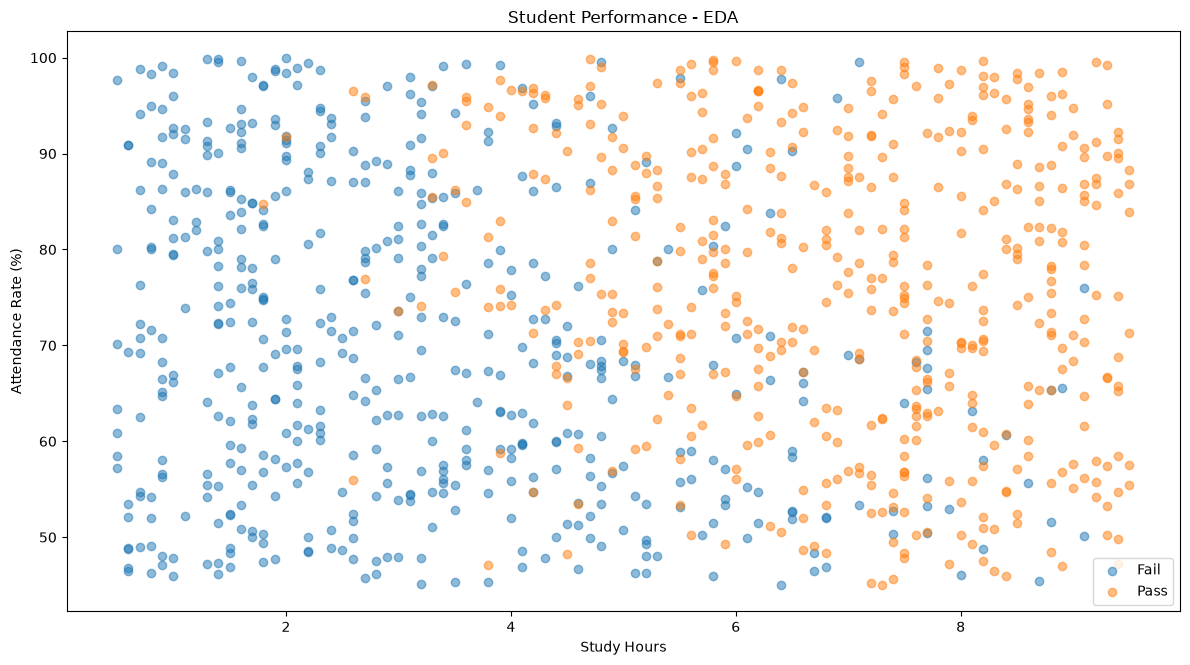

In [3]:
### 繪製學生學習表現散點圖
plt.figure(figsize=(12, 6.75))

for label, name in [(0, "Fail"), (1, "Pass")]:
    subset = df[df["passed"] == label]
    plt.scatter(
        subset["study_hours"],
        subset["attendance_rate"],
        label=name,
        alpha=0.5
    )


### 設定圖表
plt.xlabel("Study Hours")
plt.ylabel("Attendance Rate (%)")
plt.title("Student Performance - EDA")
plt.legend()
plt.tight_layout()
plt.show()

### 3. 資料清理 (Data Cleaning)

In [4]:
### 資料清理
df = df.drop_duplicates().copy() # 移除重複資料
df = df.dropna(subset=["passed"]) # 移除 Target 缺失的資料


### 查看清理結果
print(df.isnull().sum())
print("清理後資料筆數：", len(df))

study_hours           0
attendance_rate       0
practice_questions    0
sleep_hours           0
passed                0
dtype: int64
清理後資料筆數： 1000


### 4. 選擇 Features 與 Target

In [5]:
### 選擇 Features
X = df[[
    "study_hours",
    "attendance_rate",
    "practice_questions",
    "sleep_hours"
]].copy()


### 選擇 Target
y = df["passed"].astype(int).copy()


### 查看資料形狀
print("Features：", X.shape)
print("Target：", y.shape)

Features： (1000, 4)
Target： (1000,)


### 5. 切分 Train / Test

In [6]:
from sklearn.model_selection import train_test_split


### 切分 Train 80%、Test 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, # 20% 作為測試資料
    random_state=42, # 固定隨機種子
    stratify=y # 維持 Train / Test 的類別比例
)


### 查看切分結果
print("X_train：", X_train.shape)
print("X_test：", X_test.shape)
print("y_train：", y_train.shape)
print("y_test：", y_test.shape)

X_train： (800, 4)
X_test： (200, 4)
y_train： (800,)
y_test： (200,)


### 6. 建立資料前處理 Pipeline

KNN 依靠距離進行預測，因此本次一定要讓學生實際使用 StandardScaler。

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


### 建立資料前處理 Pipeline
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # 使用中位數補齊缺失值
    ("scaler", StandardScaler()) # 將 Features 標準化
])

### 7. 建立 KNN 模型

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn import set_config

### 關閉 scikit-learn 模型的 HTML 視覺化顯示
set_config(display="text")

### 建立 KNN 模型
model = Pipeline([
    ("preprocessor", preprocessor), # 資料前處理
    ("knn", KNeighborsClassifier(
        n_neighbors=5, # 尋找最近的 5 個鄰居
        weights="uniform", # 每個鄰居具有相同投票權重
        algorithm="auto", # 自動選擇近鄰搜尋演算法
        leaf_size=30, # BallTree / KDTree 的葉節點大小
        p=2, # 使用 Euclidean Distance
        metric="minkowski", # Minkowski 距離計算方式
        n_jobs=-1 # 使用所有可用 CPU 工作程序
    ))
])

### 訓練 KNN 模型
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                                 ('scaler', StandardScaler())])),
                ('knn', KNeighborsClassifier(n_jobs=-1))])

這裡有一個與 Logistic Regression 很不一樣的地方：
- Logistic Regression 需要透過最佳化演算法學習模型係數。
- KNN 則屬於 Instance-Based Learning (實例式學習)，會保存訓練資料，以便之後尋找鄰居。

因此 KNN 通常訓練速度較快，但預測時可能需要較多計算資源。

### 8. 使用模型預測

In [13]:
### 預測 Test Data
y_pred = model.predict(X_test)


### 查看前 10 筆預測結果
print(y_test[:10].to_numpy())
print(y_pred[:10])

[1 0 1 0 1 1 1 0 0 0]
[1 0 1 1 1 1 1 0 0 0]


### 9. 評估模型表現

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


### 計算分類評估指標
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)


### 顯示評估結果
print(f"Accuracy：{accuracy:.4f}")
print(f"Precision：{precision:.4f}")
print(f"Recall：{recall:.4f}")
print(f"F1-score：{f1:.4f}")


### 顯示完整分類報告
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy：0.8200
Precision：0.8333
Recall：0.7812
F1-score：0.8065
              precision    recall  f1-score   support

           0       0.81      0.86      0.83       104
           1       0.83      0.78      0.81        96

    accuracy                           0.82       200
   macro avg       0.82      0.82      0.82       200
weighted avg       0.82      0.82      0.82       200



### 10. 視覺化模型

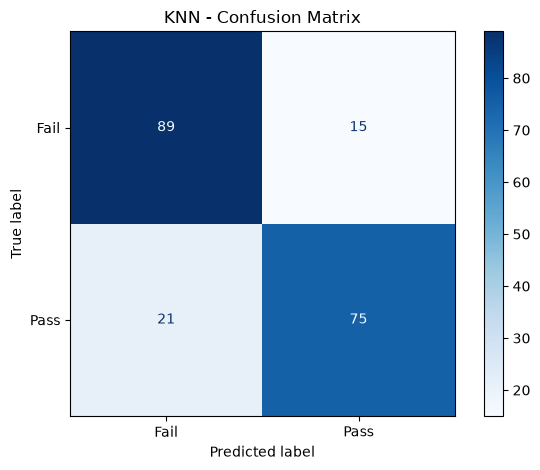

In [ ]:
#### 視覺化 Confusion Matrix 
from sklearn.metrics import ConfusionMatrixDisplay


### 繪製 Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Fail", "Pass"],
    cmap="Blues",
    values_format="d"
)


### 設定圖表
plt.title("KNN - Confusion Matrix")
plt.tight_layout()
plt.show()

## 作業：使用 KNN Classification 預測臺灣河川低溶氧狀態

本次作業使用政府資料開放平臺提供的「河川水質監測資料」，並使用 K-Nearest Neighbors Classification (KNN 分類) 建立模型，根據河川的污染物監測數值，判斷河川是否處於低溶氧狀態。

- 資料集：[河川水質監測資料](https://data.gov.tw/dataset/6078)
- 資料提供機關：環境部

```
BOD：生化需氧量
SS：懸浮固體
NH3-N：氨氮
```

預測：

```
0 → 非低溶氧狀態 (DO >= 3 mg/L)
1 → 低溶氧狀態 (DO < 3 mg/L)
```

建立以下關係：

$$\boxed{ \text{河川污染物監測數據} \longrightarrow \text{KNN Classification} \longrightarrow \text{預測是否低溶氧 (0/1)} } $$

本次將溶氧量 (DO) 低於 3 mg/L 定義為教學用的二元分類門檻，並非宣稱這是所有河川管理情境通用的法定判定標準。

學生最後的 Notebook 必須按照以下順序完成：

```text
1. 讀取資料集
        ↓
2. 探索資料 (EDA)
        ↓
3. 資料清理 (Data Cleaning)
        ↓
4. 選擇 Features 與 Target
        ↓
5. 切分 Train / Test
        ↓
6. 建立資料前處理 Pipeline
        ↓
7. 建立 KNN Classification 模型
        ↓
8. 訓練模型
        ↓
9. 使用模型預測
        ↓
10. 評估模型表現
    (Accuracy / Precision / Recall / F1-score)
        ↓
11. 視覺化預測結果
    (Confusion Matrix / ROC Curve)
```

### 作業要求

1. 使用 Pandas 讀取政府開放資料，透過 `head()`、`info()`、`describe()` 觀察資料內容。
2. 檢查缺失值、重複資料與監測值的資料型態。
3. 使用 `pivot_table()` 將 BOD、SS、NH3-N、DO 整理成同一筆監測紀錄。應先確認實際資料的監測項目代碼與單位，並處理低於偵測極限等非純數值內容。
4. 以 `DO < 3` 建立 `low_oxygen` Target，DO 缺失的資料不可直接視為非低溶氧。
5. 使用 BOD、SS、NH3-N 作為 Features，不可將 DO 或直接由 DO 計算的指標放入 Features。
6. 使用 `train_test_split()` 切分 Train 80%、Test 20%，並視類別數量使用 `stratify=y`。
7. 建立 `SimpleImputer`、`StandardScaler` 與 `KNeighborsClassifier` 的 Pipeline。
8. 設定 `n_neighbors=5`、`weights="uniform"`、`metric="minkowski"`、`p=2`，訓練 KNN 模型。
9. 使用 `predict()` 預測類別，並使用 `predict_proba()` 取得低溶氧類別的預測機率。
10. 計算 Accuracy、Precision、Recall、F1-score。
11. 繪製 Confusion Matrix 與 ROC Curve，並計算 ROC AUC。